# Stage 4 — Sensitivity Analysis

**Determining the Minimum Feasible Ballast Weight in Scuba Diving**  
Reference: *Scuba_Diving_Proposal*, Sections 4.2–4.8 and Tables 9–24.

This notebook extends the Stage 3 model by repeating the same constrained ballast optimization under the parameter scenarios defined in the report. It is self-contained: run **Kernel → Restart & Run All** without first opening the Stage 3 notebook.

**Important:** All values are theoretical model predictions under the report's assumptions, **not recommendations for actual diving, gas management, or weighting**. The input scenarios are not experimental validation.

## 1. Libraries and reusable model

All model inputs use named constants. The central `run_scenario()` function recalculates depth, ambient pressure, gas use, cylinder buoyancy, wetsuit compression, BCD limits, and the feasible ballast interval whenever a parameter changes.

**Source mapping:** pressure and gas use: Stage 2.1; wetsuit compression: Stage 2.2; constrained optimization: Stage 3; scenario modifications: Stage 4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
import numpy as np

G = 9.81
RHO0 = 1027.0
AIR_DENSITY = 1.29
PATM = 101325.0
LBF_TO_N = 4.44822
DT = 0.01
BASE_TIMES = np.array([0,2,4,6,11,12,24,25,42,43,49,50],dtype=float)
BASE_DEPTHS = np.array([0,25,25,15,15,10,10,6,6,5,5,0],dtype=float)
THICKNESS_DEPTHS = np.array([0,5,10,15,20,25],dtype=float)
SUITS={
    '3 mm': {'mass':1.136, 'B0':10.60, 'h':[3.7667,2.7378,2.2128,1.9100,1.7796,1.6492]},
    '5 mm': {'mass':3.017, 'B0':52.40, 'h':[5.1467,3.7550,2.9580,2.5037,2.2788,2.0539]},
    '7 mm': {'mass':2.910, 'B0':7.410*G, 'h':[6.9400,5.0825,4.0332,3.4275,2.8501,2.2727]},
}
CYLINDERS={
    'LAL63': {'P0':3000.0, 'volume':1783.96, 'B500_lbf':1.7},
    'LAL80': {'P0':3000.0, 'volume':2191.72, 'B500_lbf':3.4},
    'HP100': {'P0':3442.0, 'volume':2868.50, 'B500_lbf':-0.6},
}

def depth_profile(max_depth=25., bottom_time=2., duration=50.):
    times=BASE_TIMES.copy()
    depths=BASE_DEPTHS.copy()
    depths[1:3] = max_depth
    delta_bottom=bottom_time-2.0
    times[2:8] += delta_bottom # indices 2..7 (t=4,6,11,12,24,25)
    delta_duration = duration-50.0
    times[8:] += delta_duration # indices 8..11 (t=42,43,49,50)
    if np.any(np.diff(times)<=0):
        raise ValueError('Invalid profile transition times')
    return times,depths

def thickness(depth,suit='7 mm',compression=1.0):
    p=SUITS[suit]
    knots=np.asarray(p['h'],float)
    depth=np.asarray(depth)
    h=np.interp(depth,THICKNESS_DEPTHS,knots)
    # Explicitly linearly extrapolate past the 25m knot (do not silently clamp)
    h=np.where(depth>25,knots[-1]+(depth-25)*(knots[-1]-knots[-2])/5,h)
    if np.any(h<=0):
        raise ValueError('Extrapolation led to nonpositive thickness')
    return knots[0] - compression*(knots[0]-h)

def optimize_ballast(B_base,u_max):
    m_lower=max(0.,float(np.max(B_base)/G))
    m_upper=float(np.min((B_base+u_max)/G))
    feasible=m_lower<=m_upper+1e-9
    u_required=m_lower*G-B_base if feasible else None
    return {'feasible':feasible,'m_lower':m_lower,'m_upper':m_upper,
            'max_bcd':float(np.max(u_required)) if feasible else float('nan'),
            'u_required':u_required}

def run_scenario(*, rmv=15.,suit='7 mm',compression=1.,cylinder='LAL80',
                 bcd_lift=150.,bcd_inherent_lbf=1.75,body_mass=75.,body_density=985.,
                 water_density=RHO0,max_depth=25.,bottom_time=2.,duration=50.,
                 wetsuit_model='B',delta_mass=0.,delta_volume_liters=0.):
    nodes,depth_nodes=depth_profile(max_depth,bottom_time,duration)
    t=np.linspace(0,duration,round(duration/DT)+1)
    d=np.interp(t,nodes,depth_nodes)
    rho=water_density
    if rho != RHO0 and cylinder != 'LAL80':
        raise ValueError('Water-density scenarios are calibrated for the reference LAL80 cylinder only.')
    pressure_ratio=1+rho*G*d/PATM
    Q=rmv*pressure_ratio
    V_used=np.zeros_like(t)
    V_used[1:]=np.cumsum((Q[:-1]+Q[1:])*0.5*np.diff(t))
    cy=CYLINDERS[cylinder]
    B500=cy['B500_lbf']*LBF_TO_N
    B_cyl0=B500-AIR_DENSITY*G*cy['volume']*(cy['P0']-500)/cy['P0']/1000
    if rho !=RHO0:
        # Water-density comparison uses reference LAL80 external volume from report Eq. (100)
        mgas500=AIR_DENSITY*(CYLINDERS['LAL80']['volume']*500/3000)/1000
        V_cyl_ref=(14.3+0.8+mgas500+3.4*LBF_TO_N/G)/RHO0
        B_cyl0+=G*(rho-RHO0)*V_cyl_ref
    B_cyl=B_cyl0+AIR_DENSITY*G*V_used/1000
    P_cyl=cy['P0']*(1-V_used/cy['volume'])
    sp=SUITS[suit]
    if wetsuit_model=='B':
        h=thickness(d*rho/RHO0,suit,compression)
        V0=(sp['B0']+sp['mass']*G)/(RHO0*G)
        B_suit=rho*G*V0*h/sp['h'][0]-sp['mass']*G
    elif wetsuit_model=='A':
        B_suit=sp['B0']/pressure_ratio
    else: raise ValueError('Unknown wetsuit model')
    B_body=G*body_mass*(rho/body_density-1)+G*(rho*delta_volume_liters/1000-delta_mass)
    B_bcd0=bcd_inherent_lbf*LBF_TO_N
    if rho!=RHO0:
        V_bcd0=(2.6+1.75*LBF_TO_N/G)/RHO0
        B_bcd0+=G*(rho-RHO0)*V_bcd0
    u_max=bcd_lift - bcd_inherent_lbf*LBF_TO_N
    if rho!=RHO0:
        u_max*=rho/RHO0
    B_base=B_body+B_suit+B_cyl+B_bcd0
    result=optimize_ballast(B_base,u_max)
    return {**result,'time':t,'depth':d,'B_base':B_base,'B_suit':B_suit,'B_cyl':B_cyl,'P_cyl':P_cyl,
            'V_used':V_used,'bcd_u_max':u_max,'final_pressure':float(P_cyl[-1]),
            'min_at':float(t[np.argmin(B_base)]),'max_at':float(t[np.argmax(B_base)])}

def view(label, **kwargs):
    r=run_scenario(**kwargs)
    return (label,round(r['m_lower'],2),round(r['m_upper'],2),round(r['max_bcd'],2),round(r['final_pressure']))

## 2. Baseline sanity check (Stage 3)

The expected baseline is about 12.46 kg minimum ballast, 18.23 kg upper feasible bound, 85.61 N maximum required additional BCD buoyancy, and 1013 psi remaining cylinder pressure. These tests check numerical consistency with the report; they do not validate the physical model.

In [25]:
baseline=run_scenario()
assert baseline['feasible']
assert np.isclose(baseline['m_lower'],12.46,atol=0.01)
assert np.isclose(baseline['m_upper'],18.23,atol=0.01)
assert np.isclose(baseline['max_bcd'],85.61,atol=0.01)
assert np.isclose(baseline['final_pressure'],1013,atol=1)
assert np.all(baseline['u_required'] >= -1e-8)
assert np.all(baseline['u_required'] <= baseline['bcd_u_max']+1e-8)
print('Baseline validation passed.')
print('Minimum ballast (kg):',round(baseline['m_lower'],2))
print('Upper bound (kg):',round(baseline['m_upper'],2))
print('Max BCD adjustment (N):',round(baseline['max_bcd'],2))
print('Final pressure (psi):',round(baseline['final_pressure']))

Baseline validation passed.
Minimum ballast (kg): 12.46
Upper bound (kg): 18.23
Max BCD adjustment (N): 85.61
Final pressure (psi): 1013


## 3. Sensitivity scenario definitions

The grids below follow Sections 4.2–4.7 of the report.

- **Wetsuits:** different suits have different dry masses, initial buoyancies, and thickness-compression curves; they are *not* a pure thickness-only experiment.
- **Water density:** all displaced-volume, pressure, gas-consumption and BCD terms are recalculated together.
- **Dive profile:** deep time changes take time away from the 6 m shallow phase; duration changes only alter the 6 m interval, exactly as described in Section 4.7.
- **Cylinder comparison:** rated capacity, initial pressure and 500-psi buoyancy change together.

In [26]:
SCENARIOS = {
    'Wetsuit configuration': [('3 mm',{'suit':'3 mm'}),('5 mm',{'suit':'5 mm'}),('7 mm',{'suit':'7 mm'})],
    'Wetsuit compression': [('90%',{'compression':0.9}),('100%',{'compression':1.0}),('110%',{'compression':1.1})],
    'RMV': [(f'{v} L/min',{'rmv':v}) for v in (10,12,15,18,20)],
    'Cylinder': [(v,{'cylinder':v}) for v in ('LAL63','LAL80','HP100')],
    'BCD maximum lift': [(f'{v} N',{'bcd_lift':v}) for v in (130,140,150,170,200)],
    'BCD inherent buoyancy': [(f'{v} lbf',{'bcd_inherent_lbf':v}) for v in (1,1.5,1.75,2,2.5)],
    'Body density': [(f'{v} kg/m³',{'body_density':v}) for v in (975,985,995,1005,1015)],
    'Body mass': [(f'{v} kg',{'body_mass':v}) for v in (55,65,75,85,95)],
    'Water density': [(f'{v} kg/m³',{'water_density':v}) for v in (1000,1010,1024,1027,1030)],
    'Maximum depth': [(f'{v} m',{'max_depth':v}) for v in (15,20,25)],
    'Bottom time': [(f'{v} min',{'bottom_time':v}) for v in (2,4,6)],
    'Total duration': [(f'{v} min',{'duration':v}) for v in (40,50,60)],
}

def scenario_table(scenarios):
    rows=[]
    for label,parameters in scenarios:
        result=run_scenario(**parameters)
        rows.append({
            'Scenario':label,
            'Feasible':result['feasible'],
            'Min ballast (kg)':round(result['m_lower'],2),
            'Upper bound (kg)':round(result['m_upper'],2),
            'Max BCD (N)':round(result['max_bcd'],2),
            'Final pressure (psi)':round(result['final_pressure']),
        })
    return pd.DataFrame(rows)

TABLES={category:scenario_table(scenarios) for category,scenarios in SCENARIOS.items()}
print('Computed',sum(len(table) for table in TABLES.values()),'scenario rows across',len(TABLES),'categories.')

Computed 48 scenario rows across 12 categories.


## 4.2 Wetsuit sensitivity — Tables 11 and 12

In [5]:
print('Wetsuit configuration')
display(TABLES['Wetsuit configuration'])

Wetsuit configuration


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,3 mm,True,6.13,17.60,29.74,1013
1,5 mm,True,10.39,18.08,66.79,1013
2,7 mm,True,12.46,18.23,85.61,1013


In [6]:
print('Wetsuit compression')
display(TABLES['Wetsuit compression'])

Wetsuit compression


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,90%,True,12.46,18.92,78.80,1013
1,100%,True,12.46,18.23,85.61,1013
2,110%,True,12.46,17.54,92.41,1013


## 4.3 Cylinder sensitivity — Tables 13 and 15

In [7]:
print('RMV')
display(TABLES['RMV'])

RMV


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,10 L/min,True,11.84,18.20,79.77,1675
1,12 L/min,True,12.09,18.21,82.10,1410
2,15 L/min,True,12.46,18.23,85.61,1013
3,18 L/min,True,12.83,18.25,89.11,615
4,20 L/min,True,13.08,18.26,91.45,351


In [8]:
print('Cylinder')
display(TABLES['Cylinder'])

Cylinder


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,LAL63,True,12.13,17.90,85.61,559
1,LAL80,True,12.46,18.23,85.61,1013
2,HP100,True,9.84,15.61,85.61,1700


## 4.4 BCD sensitivity — Tables 16 and 17

In [9]:
print('BCD maximum lift')
display(TABLES['BCD maximum lift'])

BCD maximum lift


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,130 N,True,12.46,16.19,85.61,1013
1,140 N,True,12.46,17.21,85.61,1013
2,150 N,True,12.46,18.23,85.61,1013
3,170 N,True,12.46,20.27,85.61,1013
4,200 N,True,12.46,23.33,85.61,1013


In [10]:
print('BCD inherent buoyancy')
display(TABLES['BCD inherent buoyancy'])

BCD inherent buoyancy


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,1 lbf,True,12.12,18.23,85.61,1013
1,1.5 lbf,True,12.35,18.23,85.61,1013
2,1.75 lbf,True,12.46,18.23,85.61,1013
3,2 lbf,True,12.57,18.23,85.61,1013
4,2.5 lbf,True,12.80,18.23,85.61,1013


## 4.5 Diver sensitivity — Tables 18 and 19

In [11]:
print('Body density')
display(TABLES['Body density'])

Body density


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,975 kg/m³,True,13.26,19.03,85.61,1013
1,985 kg/m³,True,12.46,18.23,85.61,1013
2,995 kg/m³,True,11.67,17.44,85.61,1013
3,1005 kg/m³,True,10.90,16.67,85.61,1013
4,1015 kg/m³,True,10.15,15.92,85.61,1013


In [12]:
print('Body mass')
display(TABLES['Body mass'])

Body mass


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,55 kg,True,11.61,17.38,85.61,1013
1,65 kg,True,12.03,17.80,85.61,1013
2,75 kg,True,12.46,18.23,85.61,1013
3,85 kg,True,12.89,18.66,85.61,1013
4,95 kg,True,13.31,19.08,85.61,1013


## 4.6 Water-density sensitivity — Table 20

In [13]:
print('Water density')
display(TABLES['Water density'])

Water density


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,1000 kg/m³,True,9.57,15.27,82.52,1038
1,1010 kg/m³,True,10.64,16.37,83.65,1029
2,1024 kg/m³,True,12.14,17.90,85.26,1016
3,1027 kg/m³,True,12.46,18.23,85.61,1013
4,1030 kg/m³,True,12.78,18.56,85.95,1010


## 4.7 Dive-profile sensitivity — Tables 21–23

In [14]:
print('Maximum depth')
display(TABLES['Maximum depth'])

Maximum depth


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,15 m,True,12.38,19.93,68.19,1095
1,20 m,True,12.42,19.08,76.90,1054
2,25 m,True,12.46,18.23,85.61,1013


In [15]:
print('Bottom time')
display(TABLES['Bottom time'])

Bottom time


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,2 min,True,12.46,18.23,85.61,1013
1,4 min,True,12.53,18.23,86.32,935
2,6 min,True,12.61,18.23,87.04,858


In [16]:
print('Total duration')
display(TABLES['Total duration'])

Total duration


,Scenario,Feasible,Min ballast (kg),Upper bound (kg),Max BCD (N),Final pressure (psi)
0,40 min,True,12.15,18.23,82.57,1341
1,50 min,True,12.46,18.23,85.61,1013
2,60 min,True,12.77,18.23,88.64,685


## 4.8 Overall sensitivity comparison — Table 24

For each scenario family, calculate the range of the modeled minimum ballast and maximum BCD demand. The parameter ranges differ, so the ranking should **not** be interpreted as a universal measure of parameter importance.

In [17]:
overall_rows=[]
for category, table in TABLES.items():
    assert table['Feasible'].all(), f'An infeasible scenario was found in {category}'
    overall_rows.append({
        'Parameter': category,
        'Change in min ballast (kg)': round(table['Min ballast (kg)'].max() - table['Min ballast (kg)'].min(),2),
        'Change in max BCD (N)': round(table['Max BCD (N)'].max() - table['Max BCD (N)'].min(),2),
    })
overall=pd.DataFrame(overall_rows)
display(overall)

,Parameter,Change in min ballast (kg),Change in max BCD (N)
0,Wetsuit configuration,6.33,55.87
1,Wetsuit compression,0.00,13.61
2,RMV,1.24,11.68
3,Cylinder,2.62,0.00
4,BCD maximum lift,0.00,0.00
5,BCD inherent buoyancy,0.68,0.00
6,Body density,3.11,0.00
7,Body mass,1.70,0.00
8,Water density,3.21,3.43
9,Maximum depth,0.08,17.42


## 5. Automatic comparisons with the final report

These spot checks reproduce reported checkpoints from Tables 11–23 within tolerances of **0.02 kg or N** (for two-decimal values) and **1 psi** (rounded values). The 3 mm wetsuit's peak BCD result may read **29.74 N** rather than **29.75 N**, because the report lists rounded source inputs; this is a tiny numerical reporting difference, not an adjusted model assumption.

In [18]:
EXPECTED_CHECKS = [
    ({'suit':'3 mm'}, {'m_lower':6.13, 'max_bcd':29.75}),
    ({'suit':'5 mm'}, {'m_lower':10.39, 'max_bcd':66.79}),
    ({'compression':0.9}, {'max_bcd':78.80}),
    ({'compression':1.1}, {'max_bcd':92.41}),
    ({'rmv':10}, {'m_lower':11.84,'final_pressure':1675}),
    ({'rmv':20}, {'m_lower':13.08,'final_pressure':351}),
    ({'cylinder':'LAL63'}, {'m_lower':12.13,'final_pressure':559}),
    ({'cylinder':'HP100'}, {'m_lower':9.84,'final_pressure':1700}),
    ({'bcd_lift':130}, {'m_upper':16.19}),
    ({'bcd_inherent_lbf':2.5}, {'m_lower':12.80}),
    ({'body_density':975}, {'m_lower':13.26}),
    ({'body_density':1015}, {'m_lower':10.15}),
    ({'body_mass':55}, {'m_lower':11.61}),
    ({'body_mass':95}, {'m_lower':13.31}),
    ({'water_density':1000}, {'m_lower':9.57,'max_bcd':82.52,'final_pressure':1038}),
    ({'water_density':1030}, {'m_lower':12.78,'max_bcd':85.95}),
    ({'max_depth':15}, {'m_lower':12.38,'max_bcd':68.19,'final_pressure':1095}),
    ({'bottom_time':6}, {'m_lower':12.61,'max_bcd':87.04,'final_pressure':858}),
    ({'duration':40}, {'m_lower':12.15,'max_bcd':82.57,'final_pressure':1341}),
    ({'duration':60}, {'m_lower':12.77,'max_bcd':88.64,'final_pressure':685}),
]
for parameters, reference in EXPECTED_CHECKS:
    result=run_scenario(**parameters)
    assert result['feasible'], f'Infeasible: {parameters}'
    for metric, expected in reference.items():
        tolerance=1.0 if metric=='final_pressure' else 0.02
        assert abs(result[metric]-expected)<=tolerance, (
            f'Mismatch for {parameters}, {metric}: {result[metric]:.4f} vs {expected}'
        )
print(f'All {len(EXPECTED_CHECKS)} report checkpoint scenarios passed.')
print('Critical BCD lift (N):',round(baseline['max_bcd']+1.75*LBF_TO_N,2))

All 20 report checkpoint scenarios passed.
Critical BCD lift (N): 93.39


## 6. Results visualization

Show ballast mass and BCD adjustment changes in **separate charts**, because they have different units.

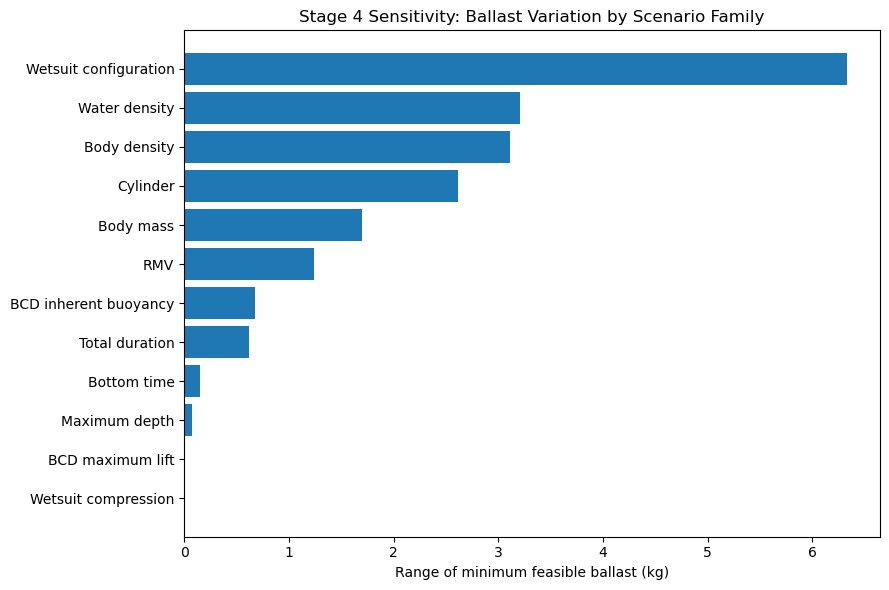

In [19]:
mass_sorted=overall.sort_values('Change in min ballast (kg)')
plt.figure(figsize=(9,6))
plt.barh(mass_sorted['Parameter'],mass_sorted['Change in min ballast (kg)'])
plt.xlabel('Range of minimum feasible ballast (kg)')
plt.title('Stage 4 Sensitivity: Ballast Variation by Scenario Family')
plt.tight_layout()
plt.show()

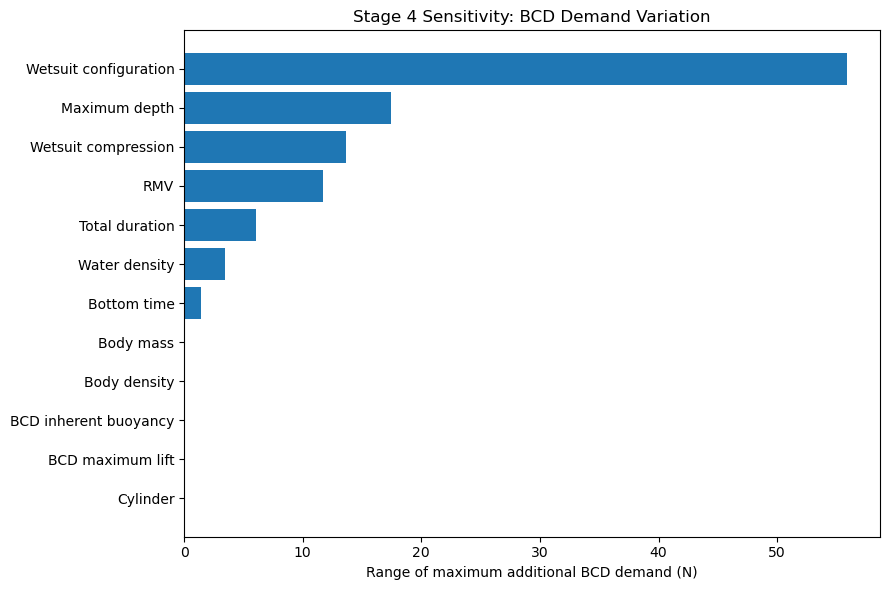

In [20]:
bcd_sorted=overall.sort_values('Change in max BCD (N)')
plt.figure(figsize=(9,6))
plt.barh(bcd_sorted['Parameter'],bcd_sorted['Change in max BCD (N)'])
plt.xlabel('Range of maximum additional BCD demand (N)')
plt.title('Stage 4 Sensitivity: BCD Demand Variation')
plt.tight_layout()
plt.show()

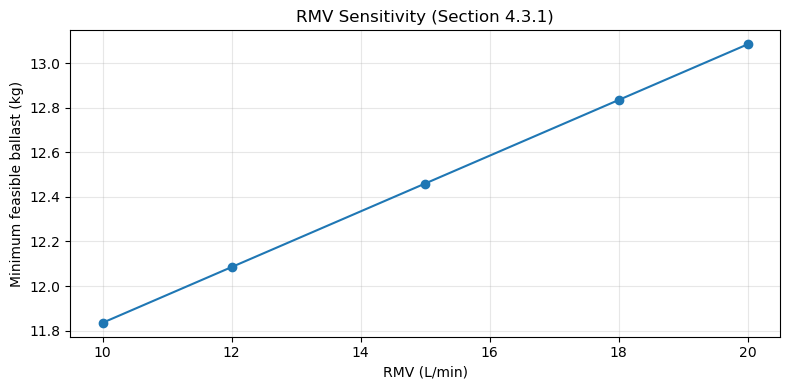

In [21]:
rmv_values=np.array([10,12,15,18,20])
rmv_ballast=np.array([run_scenario(rmv=x)['m_lower'] for x in rmv_values])
plt.figure(figsize=(8,4))
plt.plot(rmv_values,rmv_ballast,marker='o')
plt.xlabel('RMV (L/min)')
plt.ylabel('Minimum feasible ballast (kg)')
plt.title('RMV Sensitivity (Section 4.3.1)')
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

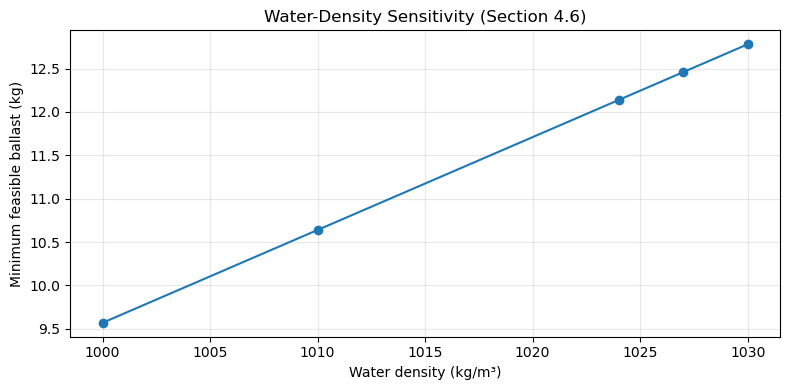

In [22]:
rho_values=np.array([1000,1010,1024,1027,1030])
rho_ballast=np.array([run_scenario(water_density=x)['m_lower'] for x in rho_values])
plt.figure(figsize=(8,4))
plt.plot(rho_values,rho_ballast,marker='o')
plt.xlabel('Water density (kg/m³)')
plt.ylabel('Minimum feasible ballast (kg)')
plt.title('Water-Density Sensitivity (Section 4.6)')
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Short-term body change example (Section 4.5.3)

The report illustrates an assumed +1 kg body mass accompanied by +1 L displaced volume: $\Delta m_b^* = 1027(0.001)-1=0.027$ kg. This is an illustrative *specified* change, not a prediction of what eating or drinking does to a person.

In [23]:
short_term=run_scenario(delta_mass=1.0,delta_volume_liters=1.0)
delta_ballast=short_term['m_lower']-baseline['m_lower']
print('Change in modeled minimum ballast (kg):',round(delta_ballast,3))
assert np.isclose(delta_ballast,0.027,atol=1e-8)

Change in modeled minimum ballast (kg): 0.027


## 8. Export for GitHub

Save numerical tables as CSV, if desired, so readers can inspect results independently of the notebook. Run this cell from your project folder.

**Caution:** mathematical feasibility does not imply sufficient breathing-gas reserve, no-decompression compliance, controlled ascent, or real-world ballast safety. The modeled 1000-psi value is an illustrative comparison, **not a universally safe threshold**.

In [24]:
from pathlib import Path
export_dir=Path('stage4_outputs')
export_dir.mkdir(exist_ok=True)
for category,table in TABLES.items():
    filename=category.lower().replace(' ','_').replace('-','_')+'.csv'
    table.to_csv(export_dir/filename,index=False)
overall.to_csv(export_dir/'overall_sensitivity.csv',index=False)
print('Exported tables to:',export_dir.resolve())

Exported tables to: /Users/lyc/Desktop/stage4_outputs


### Notes on model scope

- Whole-suit buoyancy at depth has not been experimentally validated. Wetsuit compression measurements originate from different material specimens and 20–25 m values are extrapolated.
- BCD inherent buoyancy and displaced volumes contain assumptions, and BCD inflation gas usage is not coupled to the cylinder inventory.
- The one-at-a-time scenario families change different parameter ranges and should not be compared as standardized sensitivities.
- The 50-minute profile is an illustrative mathematical trajectory, not an operational dive plan.

**For GitHub:** upload this `.ipynb`, your Stage 3 notebook, the full PDF report, and a `requirements.txt` listing `numpy`, `pandas`, `matplotlib`, and `ipykernel`.